In [1]:
from catboost import CatBoostClassifier
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.metrics import f1_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [2]:
import catboost

In [3]:
df = pd.read_csv("Data/data_kern.csv")

In [4]:
df

,Calibration,Well,Sample,Depth,Stratigraphy,Mg,Al,Si,P,S,...,Sr,Zr,Mo,Ba,Pb,Th,U,Y,Cd,V
0,LE-FP,C3,1,2868.11,Fr,1.821148,7.515664,18.611483,0.299690,10.465318,...,0.017295,0.005169,0.006378,0.390684,0.0011,0.0034,0.0330,NaN,NaN,0.0
1,LE-FP,C3,2,2868.30,Fr,1.266357,7.461183,16.904798,0.000000,14.653735,...,0.009028,0.003092,0.007169,0.179474,0.0019,0.0000,0.0012,NaN,NaN,0.0
2,LE-FP,C3,3,2868.45,Fr,1.724880,7.150965,18.068731,0.000000,13.442425,...,0.018256,0.005030,0.006039,0.522104,0.0015,0.0000,0.0018,NaN,NaN,0.0
3,LE-FP,C3,4,2868.64,Fr,1.646439,8.260792,21.260196,0.000000,10.257598,...,0.011463,0.004061,0.005446,0.222917,0.0021,0.0000,0.0017,NaN,NaN,0.0
4,LE-FP,C3,5,2868.78,Fr,1.847176,7.757235,19.837340,0.000000,10.623499,...,0.016122,0.002446,0.006519,0.494492,0.0023,0.0000,0.0036,NaN,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3111,LE-FP,C7,362,2697.50,Tum,1.583924,10.335025,27.434503,0.029277,0.622963,...,0.012094,0.011722,0.000000,0.158503,NaN,NaN,NaN,NaN,NaN,NaN
3112,LE-FP,C7,363,2697.78,Tum,1.491458,7.860884,29.874495,0.020000,0.691707,...,0.011974,0.007845,0.000000,0.133802,NaN,NaN,NaN,NaN,NaN,NaN
3113,LE-FP,C7,364,2697.84,Tum,1.459012,11.210366,28.113407,0.052834,0.137574,...,0.012214,0.015968,0.000000,0.160868,NaN,NaN,NaN,NaN,NaN,NaN
3114,LE-FP,C7,365,2698.97,Tum,1.300348,1.489742,2.630132,0.000000,31.978827,...,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


**Отобранные элементы с доставерными определениями**

In [5]:
elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

In [6]:
cols_to_keep = elements + ['Well', 'Sample',	'Depth',	'Stratigraphy']
df_filtered = df[cols_to_keep].query("Stratigraphy != 'Tum'").copy()

**Замена пачек на цифровые коды**

In [7]:
def to_str_key(val):
    try:
        return str(int(val))
    except (ValueError, TypeError):
        return str(val).strip()

df_filtered['Strat'] = df_filtered['Stratigraphy'].apply(to_str_key)

In [8]:
formation_map = {
    'Abl': 0,
    'A0': 1,
    '1': 2,
    '2a': 3,
    '2b': 4,
    '3': 5,
    '4a': 6,
    '4b': 7,
    '5a': 8,
    '5b': 9,
    '6': 10,
    'Fr': 11
}

df_filtered['Strat'] = df_filtered['Strat'].map(formation_map)

**Кросс-валидация по скважинам с фиксированным набором параметров**

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2452 проб, Val: 647 проб
F1 macro (train): 0.9816
F1 macro (val):   0.4697
Gap (train-val):  0.5119

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9730    0.5714    0.7200       126
           1     0.4054    0.2941    0.3409        51
           2     0.2353    0.6087    0.3394        46
           3     0.7206    0.6806    0.7000        72
           4     0.6829    0.6222    0.6512        45
           5     0.0000    0.0000    0.0000         7
           6     0.4667    0.3256    0.3836        43
           7     0.5556    0.2703    0.3636        37
           8     0.4318    0.3800    0.4043        50
           9     0.4861    0.8861    0.6278        79
          10     0.8837    0.5278    0.6609        72
          11     0.4706    0.4211    0.4444        19

    accuracy                    

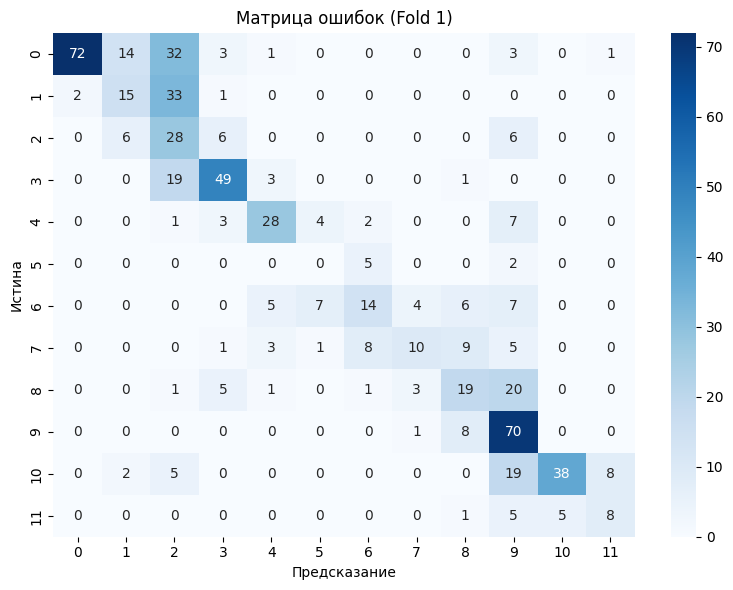

Fold 2
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A3', 'C2', 'C7']
  Train: 2439 проб, Val: 660 проб
F1 macro (train): 0.9843
F1 macro (val):   0.6690
Gap (train-val):  0.3152

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.7978    0.9103    0.8503        78
           1     0.8077    0.4773    0.6000        44
           2     0.6800    0.6800    0.6800        50
           3     0.7703    0.7917    0.7808        72
           4     0.6517    0.7532    0.6988        77
           5     0.5556    0.4054    0.4688        37
           6     0.3889    0.2500    0.3043        28
           7     0.4286    0.5357    0.4762        28
           8     0.6000    0.6375    0.6182        80
           9     0.7636    0.7925    0.7778       106
          10     0.8286    0.8056    0.8169        36
          11     1.0000    0.9167    0.9565        24

    accuracy                    

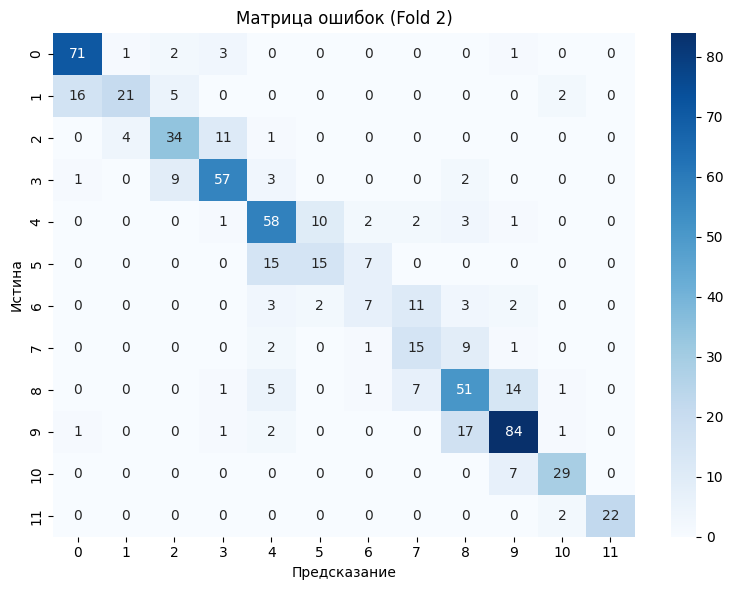

Fold 3
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['B1', 'C1', 'C4']
  Train: 2493 проб, Val: 606 проб
F1 macro (train): 0.9839
F1 macro (val):   0.5567
Gap (train-val):  0.4271

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9306    0.9710    0.9504        69
           1     0.3636    0.2857    0.3200        14
           2     0.4717    0.6250    0.5376        40
           3     0.6400    0.6400    0.6400        50
           4     0.7879    0.4815    0.5977        54
           5     0.5600    0.3889    0.4590        36
           6     0.2941    0.5556    0.3846        18
           7     0.3000    0.1579    0.2069        38
           8     0.5385    0.5600    0.5490        75
           9     0.6538    0.7816    0.7120        87
          10     0.6027    0.7213    0.6567        61
          11     0.7358    0.6094    0.6667        64

    accuracy                    

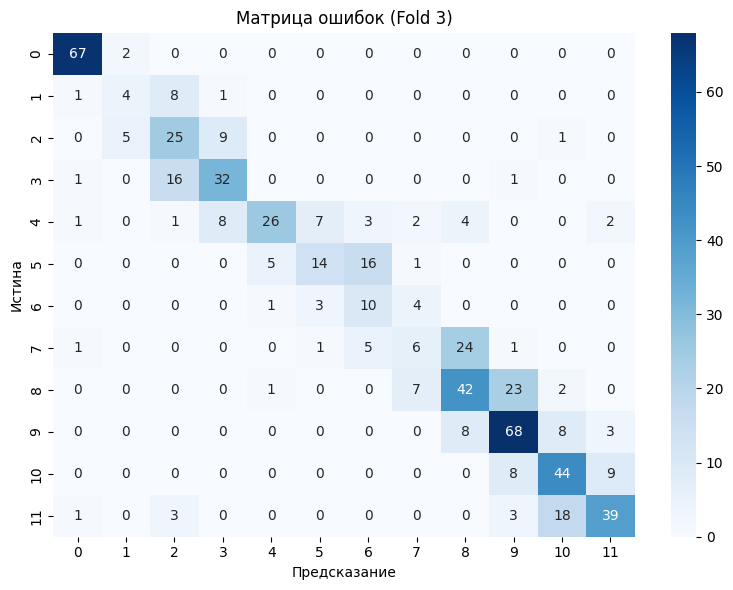

Fold 4
  Train wells: ['A1', 'A3', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'A4', 'C5']
  Train: 2500 проб, Val: 599 проб
F1 macro (train): 0.9808
F1 macro (val):   0.5794
Gap (train-val):  0.4014

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9574    0.9375    0.9474        96
           1     0.6667    0.4211    0.5161        19
           2     0.6842    0.9286    0.7879        28
           3     0.8485    0.8750    0.8615        32
           4     0.4423    0.7419    0.5542        31
           5     0.2750    0.2444    0.2588        45
           6     0.3636    0.1951    0.2540        41
           7     0.3333    0.1333    0.1905        60
           8     0.5691    0.6087    0.5882       115
           9     0.6396    0.8353    0.7245        85
          10     0.8163    0.9302    0.8696        43
          11     1.0000    0.2500    0.4000         4

    accuracy                    

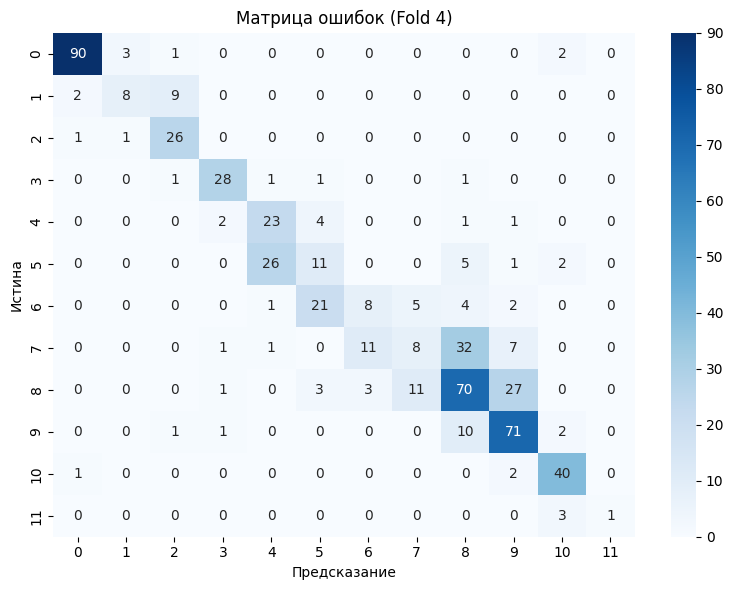

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C4', 'C5', 'C7', 'E1']
  Val wells:   ['C3', 'C6', 'D1']
  Train: 2512 проб, Val: 587 проб
F1 macro (train): 0.9782
F1 macro (val):   0.5841
Gap (train-val):  0.3941

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.8209    0.9016    0.8594        61
           1     0.6000    0.4444    0.5106        27
           2     0.4167    0.5172    0.4615        29
           3     0.8372    0.8182    0.8276        44
           4     0.7059    0.8276    0.7619        29
           5     0.3600    0.4500    0.4000        20
           6     0.2778    0.2500    0.2632        20
           7     0.3636    0.2857    0.3200        28
           8     0.3839    0.5972    0.4674        72
           9     0.6404    0.5448    0.5887       134
          10     0.8966    0.6047    0.7222        86
          11     0.8158    0.8378    0.8267        37

    accuracy                    

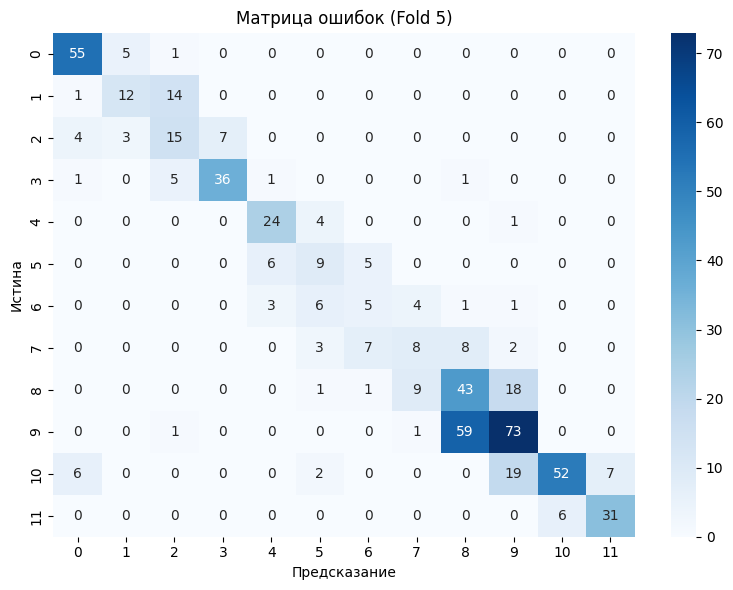

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4697
  Fold 2: F1_macro = 0.6690
  Fold 3: F1_macro = 0.5567
  Fold 4: F1_macro = 0.5794
  Fold 5: F1_macro = 0.5841

  Средний F1 macro: 0.5718 ± 0.0638

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.8965    0.8256    0.8596       430
           1     0.5660    0.3871    0.4598       155
           2     0.4324    0.6632    0.5235       193
           3     0.7537    0.7481    0.7509       270
           4     0.6386    0.6737    0.6557       236
           5     0.3798    0.3379    0.3577       145
           6     0.3607    0.2933    0.3235       150
           7     0.3950    0.2461    0.3032       191
           8     0.5090    0.5740    0.5396       392
           9     0.6278    0.7454    0.6816       491
          10     0.7868    0.6812    0.7302       298
          11     0.7710    0.6824    0.7240       148

    accuracy                         0.6257      

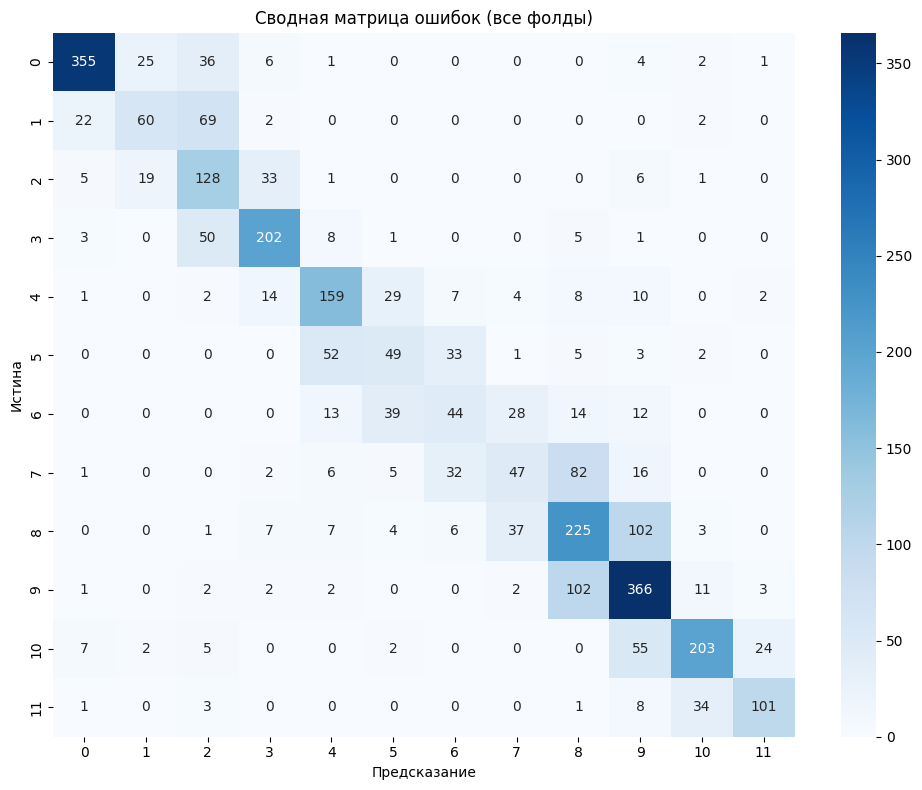

In [14]:
X = df_filtered[elements]
y = df_filtered['Strat']
groups = df_filtered['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)
 
    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)
   
    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df_filtered.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df_filtered.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df_filtered.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df_filtered.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)
    
    results_df_list.append(df_vl)
    

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV 
results_df = pd.concat(results_df_list, ignore_index=True)
results_df.to_csv('Result/classification_results_CatBoost_fixed.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()